# 04 — Post-Build Quality Catalog & `CombinedECGDataset` Smoke Test

Full audit of `combined/quality/error_labels.csv.gz` and live verification of `CombinedECGDataset` quality filtering (`load_error_labels`, `max_error_severity`, `exclude_error_flags`).

=== Severity Tier Breakdown ===


,count
severity_tier,
0_clean,126374
1_minor_warning,419745
2_moderate_anomaly,1333


,count,pct
err_meta_labels_missing,419441,76.62
err_meta_sex_missing,419441,76.62
err_meta_age_missing,419441,76.62
err_sig_clipped_amplitude,1257,0.23
err_spec_residual_wander,543,0.10
err_sig_lead_physics_violation,92,0.02
err_spec_residual_hf,1,0.00
err_sig_nan_or_inf,0,0.00
err_sig_flatline_lead,0,0.00
err_spec_residual_mains,0,0.00


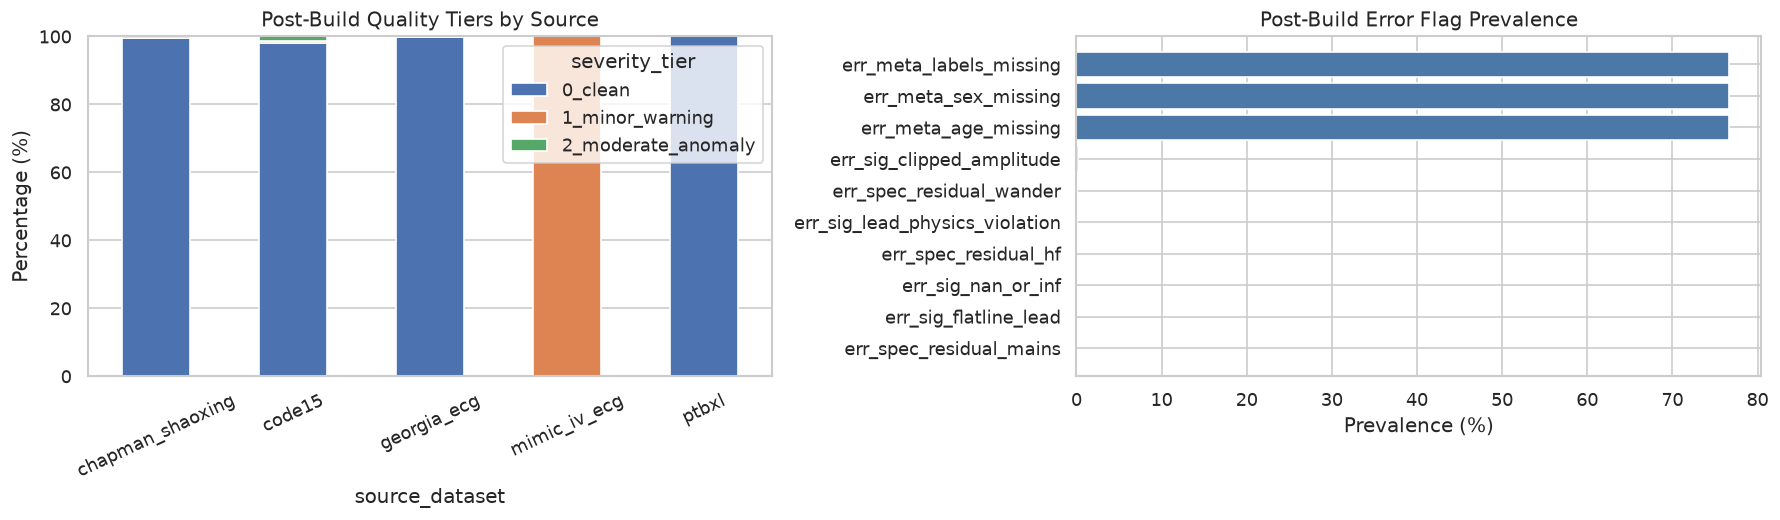

/nfs/data8/schlegel/git/ecg-data-repo/combined/dataset.py:78: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(meta_path)


/nfs/data8/schlegel/git/ecg-data-repo/combined/dataset.py:78: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(meta_path)


CombinedECGDataset: all=547,452 | max_sev<=2=547,452 | clean_only=126,374
Sample[0] keys: ['signal', 'source_dataset', 'source_record_id', 'patient_id', 'labels', 'meta', 'error_labels'] | signal: (12, 5000) | tier: 0_clean


In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "combined" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate combined/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from combined import CombinedECGDataset
COMBINED_DIR = REPO_ROOT / "combined"
DATA_DIR = COMBINED_DIR / "data"
QUALITY_DIR = COMBINED_DIR / "quality"
LEADS = CombinedECGDataset.LEADS

err = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz")
flag_cols = [c for c in err.columns if c.startswith("err_")]

print("=== Severity Tier Breakdown ===")
display(err["severity_tier"].value_counts().sort_index().to_frame("count"))

flag_summary = pd.DataFrame({
    "count": err[flag_cols].sum().astype(int),
    "pct": (100 * err[flag_cols].mean()).round(2),
}).sort_values("count", ascending=False)
display(flag_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ct = pd.crosstab(err["source_dataset"], err["severity_tier"], normalize="index") * 100
ct.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title("Post-Build Quality Tiers by Source")
axes[0].tick_params(axis="x", rotation=25)

axes[1].barh(flag_summary.index, flag_summary["pct"], color="#4c78a8")
axes[1].invert_yaxis()
axes[1].set_xlabel("Prevalence (%)")
axes[1].set_title("Post-Build Error Flag Prevalence")
plt.tight_layout()
plt.show()

# Live CombinedECGDataset quality-filter smoke test
ds_all = CombinedECGDataset(load_error_labels=True)
ds_no_sev = CombinedECGDataset(max_error_severity=2)
ds_clean = CombinedECGDataset(max_error_severity=0)
print(f"CombinedECGDataset: all={len(ds_all):,} | max_sev<=2={len(ds_no_sev):,} | clean_only={len(ds_clean):,}")
s0 = ds_all[0]
print("Sample[0] keys:", list(s0.keys()), "| signal:", s0["signal"].shape, "| tier:", s0["error_labels"]["severity_tier"])
